# Appendix A | Worked solutions

*Notation and Tensor Shapes*

A tensor can have the right dimensions and still carry the wrong information. These solutions track token membership, distinguish query and key masks, and use independent numerical references to catch mistakes.

Eight exercises progress from tracing small calculations to diagnosing implementation errors. These are controlled numerical examples, not performance or model-quality benchmarks.

## Setup

Run all cells in order from anywhere inside the companion repository. The written PDF contains every problem, explanation, and plot; the notebook PDF adds the code and saved outputs. NumPy and Matplotlib are required; Appendix C also uses PyTorch. No downloads, credentials, GPU, or trained checkpoint are needed.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "examples/ch04_attention/attention.py").exists())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcdefaults()
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
from examples.ch04_attention.attention import stable_softmax, scaled_dot_product_attention


## 1. Project each token

**Problem.** An input has four token rows and five features. Give the weight and output shapes for two output features per token. Why is the first output row independent of the other inputs?

**Solution.** $X$ is $4\times5$, so $W$ must be $5\times2$ and $Y=XW$ is $4\times2$. In $Y_{1j}=\sum_{r=1}^5X_{1r}W_{rj}$, only the first input row appears. The same learned matrix acts on every row; sharing parameters does not mix the inputs. Changing the fourth token leaves the first output row unchanged.

In [2]:
x = np.arange(20).reshape(4, 5)
w = np.arange(10).reshape(5, 2)
y = x @ w
changed = x.copy(); changed[3] += 100
assert w.shape == (5, 2) and y.shape == (4, 2)
np.testing.assert_array_equal((changed @ w)[0], y[0])
print("W shape:", w.shape, "Y shape:", y.shape)
print("First output row is unchanged:", y[0])

W shape: (5, 2) Y shape: (4, 2)
First output row is unchanged: [60 70]


## 2. Name the attention axes

**Problem.** $Q$, $K$, and $V$ have shapes $[3,2,4,5]$, $[3,2,7,5]$, and $[3,2,7,6]$. Give the transposed-key, score, and output shapes, and the normalized axis.

**Solution.** The last two axes of $K$ exchange places, giving $[3,2,5,7]$. Multiplication produces scores $[3,2,4,7]$, one score for each query/key pair. Softmax normalizes the last axis, the seven keys. Multiplying by $V$ gives $[3,2,4,6]$. The batch and head axes remain unchanged. Values determine output width; keys determine how many weights each query needs.

In [3]:
rng = np.random.default_rng(7)
q, k, v = [rng.normal(size=s) for s in
           [(3, 2, 4, 5), (3, 2, 7, 5), (3, 2, 7, 6)]]
out, weights = scaled_dot_product_attention(q, k, v)
np.testing.assert_allclose(weights.sum(axis=-1), 1)
assert out.shape == (3, 2, 4, 6)
print("K transposed:", k.swapaxes(-2, -1).shape)
print("Scores/weights:", weights.shape, "Output:", out.shape)

K transposed: (3, 2, 5, 7)
Scores/weights: (3, 2, 4, 7) Output: (3, 2, 4, 6)


## 3. Separate two masks

**Problem.** Queries are at absolute positions $(3,4,5)$ and keys at $(2,3,4,5)$. Position 5 is padding. Give the combined causal/key mask and query validity; explain where each applies.

**Solution.** A key is allowed when its position is no later than the query and it is valid. The three rows are $(1,1,0,0)$, $(1,1,1,0)$, and $(1,1,1,0)$. Query validity is $(1,1,0)$. The first mask acts before softmax on score columns. Query validity discards the third output row afterward. That padded query still has allowed keys, so computing its softmax first is defined. An entirely empty row would require a different policy, not multiplication by zero after a NaN.

Allowed mask:
 [[1 1 0 0]
 [1 1 1 0]
 [1 1 1 0]]
Query validity: [1 1 0]


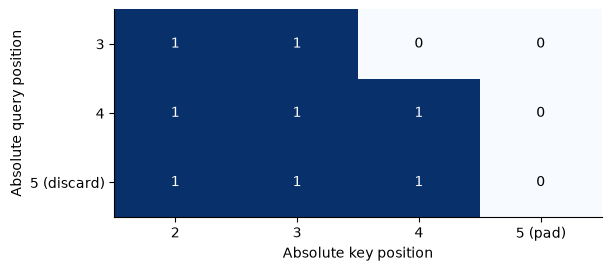

In [4]:
qp = np.array([3, 4, 5]); kp = np.array([2, 3, 4, 5])
allowed = (kp[None, :] <= qp[:, None]) & (kp[None, :] != 5)
valid_query = qp != 5
np.testing.assert_array_equal(allowed,
                             [[1,1,0,0], [1,1,1,0], [1,1,1,0]])
assert allowed.any(axis=-1).all()
print("Allowed mask:\n", allowed.astype(int))
print("Query validity:", valid_query.astype(int))
fig, ax = plt.subplots(figsize=(6, 2.6), layout="constrained")
ax.imshow(allowed, cmap="Blues", vmin=0, vmax=1, aspect="auto")
for i in range(3):
    for j in range(4):
        ax.text(j, i, int(allowed[i,j]), ha="center", va="center",
                color="white" if allowed[i,j] else "black")
ax.set(xticks=range(4), xticklabels=["2", "3", "4", "5 (pad)"],
       yticks=range(3), yticklabels=["3", "4", "5 (discard)"],
       xlabel="Absolute key position", ylabel="Absolute query position")
plt.show()

## 4. Count a cache

**Problem.** One layer, one example, and one KV head store two key and three value coordinates per token. Count scalars for a prefix of six and identify the growing axis.

**Solution.** Each token contributes $2+3=5$ scalars. Six positions require $6(5)=30$, split into 12 key and 18 value scalars. Extending the prefix grows the retained-position axis; it does not change feature width or parameter shape. This is a payload count, before any unused capacity or metadata.

In [5]:
key_shape = (1, 1, 6, 2); value_shape = (1, 1, 6, 3)
count = np.prod(key_shape) + np.prod(value_shape)
assert count == 30
print("Keys:", np.prod(key_shape), "Values:", np.prod(value_shape))
print("Total cache scalars:", count)

Keys: 12 Values: 18
Total cache scalars: 30


## 5. Preserve token membership

**Problem.** Fill $[2,3,4]$ with integers 0 through 23. Split into two heads correctly and by direct reshape to $[2,2,3,2]$. Compare entry `[1,0,2,:]` and undo the correct split.

**Solution.** First split only the feature axis: $[B,T,D]\to[B,T,H,d]$. Then exchange token and head: $[B,T,H,d]\to[B,H,T,d]$. The requested correct entry is $(20,21)$; direct reshaping yields $(16,17)$. To merge, exchange the axes back and join the feature axes. Equality of the whole recovered array checks membership, not just dimensions.

In [6]:
x = np.arange(24).reshape(2, 3, 4)
heads = x.reshape(2, 3, 2, 2).swapaxes(1, 2)
wrong = x.reshape(2, 2, 3, 2)
merged = heads.swapaxes(1, 2).reshape(2, 3, 4)
np.testing.assert_array_equal(heads[1,0,2], [20,21])
np.testing.assert_array_equal(wrong[1,0,2], [16,17])
np.testing.assert_array_equal(merged, x)
print("Correct:", heads[1,0,2], "Direct reshape:", wrong[1,0,2])
print("Every original entry recovered:", np.array_equal(merged, x))

Correct: [20 21] Direct reshape: [16 17]
Every original entry recovered: True


## 6. Catch silent broadcasting

**Problem.** Scores have shape $[2,1,2,2]$ and key-validity rows $(1,0)$ and $(1,1)$. Compare broadcasting the raw $[2,2]$ mask with inserting batch-preserving singleton axes.

**Solution.** The raw mask aligns its first axis with queries, because broadcasting aligns from the right. Thus query 0 in both examples receives $(1,0)$ and query 1 receives $(1,1)$. The intended mask has shape $[2,1,1,2]$: both queries of example 0 get $(1,0)$, and both of example 1 get $(1,1)$. Example 0, query 1 wrongly reads its padded key in the raw version. Example 1, query 0 wrongly loses a valid key.

In [7]:
valid = np.array([[True, False], [True, True]])
raw = np.broadcast_to(valid, (2, 1, 2, 2))
intended = np.broadcast_to(valid[:,None,None,:], (2, 1, 2, 2))
assert raw[0,0,1,1] and not intended[0,0,1,1]
assert not raw[1,0,0,1] and intended[1,0,0,1]
print("Raw mask, by example:\n", raw[:,0].astype(int))
print("Intended mask, by example:\n", intended[:,0].astype(int))

Raw mask, by example:
 [[[1 0]
  [1 1]]

 [[1 0]
  [1 1]]]
Intended mask, by example:
 [[[1 0]
  [1 0]]

 [[1 1]
  [1 1]]]


## 7. Trace a weighted read

**Problem.** Use query $(1,0)$, keys $(1,0),(0,1),(1,1)$, and values $(10,0),(0,20),(30,30)$. Compute weights and output; mask the second key, then change its value.

**Solution.** Write $u=e^{1/\sqrt2}$. The unmasked weights are $(u,1,u)/(2u+1)$, approximately $(0.401112,0.197776,0.401112)$. The output is approximately $(16.04448,15.98888)$. Removing the second key leaves equal first and third scores, so their weights become $1/2$ each and the output is $(20,15)$. Changing the excluded value or key cannot affect valid outputs, provided the implementation still accepts the finite inputs.

Weights: [0.401112 0.197776 0.401112] Output: [16.044484 15.988879]
Masked weights: [0.5 0.  0.5] Output: [20. 15.]


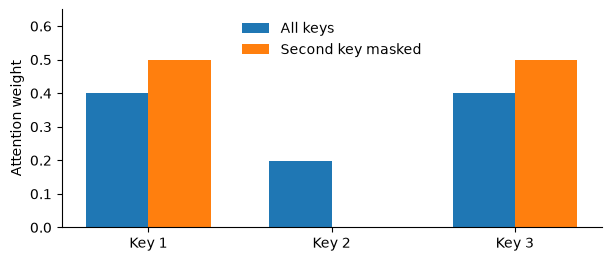

In [8]:
q = np.array([[1.,0.]])
k = np.array([[1.,0.], [0.,1.], [1.,1.]])
v = np.array([[10.,0.], [0.,20.], [30.,30.]])
out, weights = scaled_dot_product_attention(q,k,v)
masked, mw = scaled_dot_product_attention(q,k,v, [[True,False,True]])
np.testing.assert_allclose(weights.sum(-1), 1)
np.testing.assert_allclose(masked, [[20,15]])
changed_v = v.copy(); changed_v[1] = [1e6,-1e6]
changed_k = k.copy(); changed_k[1] = [-1000,2000]
again, _ = scaled_dot_product_attention(q,changed_k,changed_v,
                                       [[True,False,True]])
np.testing.assert_allclose(again, masked)
print("Weights:", weights[0], "Output:", out[0])
print("Masked weights:", mw[0], "Output:", masked[0])
fig, ax = plt.subplots(figsize=(6,2.5), layout="constrained")
positions = np.arange(3)
ax.bar(positions-.17,weights[0],width=.34,label="All keys")
ax.bar(positions+.17,mw[0],width=.34,label="Second key masked")
ax.set(xticks=positions,xticklabels=["Key 1","Key 2","Key 3"],
       ylabel="Attention weight",ylim=(0,.65))
ax.legend(frameon=False); plt.show()

## 8. Audit an axis port

**Problem.** A port uses `K.T` on $[3,2,7,5]$ and softmax over the query axis. Give the actual and intended transpose shapes and numerical tests even when lengths coincide.

**Solution.** NumPy `.T` reverses all axes: $[5,7,2,3]$. The intended exchange gives $[3,2,5,7]$. Compare scores against explicit indexed dot products (or an independent einsum) with distinct values in each batch, head, and position. To check softmax, compare row sums over keys with one and compare against a per-query reference. Normalizing queries instead makes column sums one; with unequal scores the key-row sums generally differ from one. Equal axis sizes can hide the shape mistake, so the numerical check is essential.

In [9]:
rng = np.random.default_rng(19)
q = rng.normal(size=(2,2,2,2)); k = rng.normal(size=(2,2,2,2))
reference = np.einsum("bhqd,bhkd->bhqk", q, k)
correct = q @ k.swapaxes(-2,-1)
wrong = q @ k.T
np.testing.assert_allclose(correct, reference, atol=1e-14)
assert not np.allclose(wrong, reference)
right_weights = stable_softmax(reference)
wrong_weights = stable_softmax(reference.swapaxes(-2,-1)).swapaxes(-2,-1)
np.testing.assert_allclose(right_weights.sum(-1), 1)
assert not np.allclose(wrong_weights.sum(-1), 1)
print("K.T shape for original problem:", np.zeros((3,2,7,5)).T.shape)
print("Wrong-axis key-row sums:", wrong_weights.sum(-1))
print("Independent score and normalization checks catch both errors.")

K.T shape for original problem: (5, 7, 2, 3)
Wrong-axis key-row sums: [[[0.903049 1.096951]
  [0.927206 1.072794]]

 [[0.484925 1.515075]
  [1.668203 0.331797]]]
Independent score and normalization checks catch both errors.
